# Natural Language Processing — Practical Exam (Set B)
## Airline Tweet Analytics: From Raw Text to Streamlit App

**Dataset:** [Twitter US Airline Sentiment (`Tweets.csv`)](https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment)  
**Note:** Place `Tweets.csv` and `nlp_helpers.py` in the same folder as this notebook before running top-to-bottom.


In [13]:
!pip install gensim

In [14]:
import os
import re
from collections import Counter
import zipfile
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from gensim.models import Word2Vec
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from textblob import TextBlob

# Download required NLTK resources once
for pkg in [
    "punkt",
    "punkt_tab",
    "stopwords",
    "wordnet",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng",
]:
    nltk.download(pkg, quiet=True)

from nlp_helpers import clean_text

os.makedirs("outputs", exist_ok=True)
sns.set_theme(style="whitegrid")
print(f"scikit-learn version: {sklearn.__version__}")


scikit-learn version: 1.6.1


---
## Step 1: NLP Fundamentals, Text Preprocessing & Regular Expressions (RegEx)

### 1.1 Theory Notes

**What is NLP and why do businesses need it?**  
Natural Language Processing (NLP) is a branch of artificial intelligence that enables computers to read, understand, interpret, and generate human language. Businesses need NLP because most customer feedback—such as tweets, support tickets, reviews, and chat logs—is unstructured text that cannot be analysed at scale manually.

**Three Real-World Applications of NLP:**
1. **Voice Assistants** (e.g., Siri, Alexa, Google Assistant) — converting spoken commands into structured actions.
2. **Email Spam & Phishing Filters** — classifying incoming messages using text patterns and metadata.
3. **Machine Translation** — translating regional and global languages in real time (e.g., English to Hindi/Gujarati).

**Four Key Challenges in NLP (with Examples):**
1. **Ambiguity:** Words change meaning by context — *"The flight delay was long"* (noun) vs *"Do not delay my flight"* (verb).
2. **Sarcasm & Irony:** Surface words look positive while the intent is negative — *"Oh great, another 5-hour delay! Just what I needed #ThanksAirline."*
3. **Slang & Spelling Mistakes:** Informal social media text breaks standard dictionaries — *"dis flite iz soooo lateee smh."*
4. **Hinglish Code-Mixing:** Mixing Hindi and English in Roman script — *"Flight late hai, service bilkul bakwaas thi."*

**Stages of a Basic NLP Pipeline:**  
`Raw Text` → `Text Cleaning & RegEx` → `Tokenisation` → `Stop-word Removal & Lemmatization` → `Feature Extraction (BoW / TF-IDF / Embeddings)` → `ML Model Training` → `Evaluation & Prediction`


### 1.2 Load & Explore `Tweets.csv`


In [15]:
!kaggle datasets download crowdflower/twitter-airline-sentiment

Dataset URL: https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment
License(s): CC-BY-NC-SA-4.0
twitter-airline-sentiment.zip: Skipping, found more recently modified local copy (use --force to force download)


In [16]:
parent = Path.cwd()

In [17]:
zip_path = parent / 'twitter-airline-sentiment.zip'
dir_path = parent / 'Dataset'

In [18]:
with zipfile.ZipFile(zip_path,'r') as zip_ref:
  zip_ref.extractall(dir_path)
print('Dataset Extracted')

Dataset Extracted


In [20]:
cols = ["airline", "airline_sentiment", "negativereason", "text"]
df = pd.read_csv("Dataset/Tweets.csv", usecols=cols)

print("Dataset shape:", df.shape)
display(df.head(5))
print("\nSentiment counts:")
print(df["airline_sentiment"].value_counts())


Dataset shape: (14640, 4)


,airline_sentiment,negativereason,airline,text
0,neutral,NaN,Virgin America,@VirginAmerica What @dhepburn said.
1,positive,NaN,Virgin America,@VirginAmerica plus you've added commercials t...
2,neutral,NaN,Virgin America,@VirginAmerica I didn't today... Must mean I n...
3,negative,Bad Flight,Virgin America,@VirginAmerica it's really aggressive to blast...
4,negative,Can't Tell,Virgin America,@VirginAmerica and it's a really big bad thing...



Sentiment counts:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


Percentage of negative tweets: 62.69%


/tmp/ipykernel_654/2593731575.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


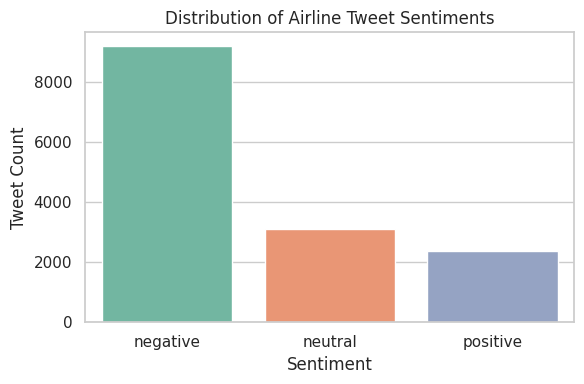

In [21]:
sentiment_counts = df["airline_sentiment"].value_counts()
neg_pct = (sentiment_counts["negative"] / len(df)) * 100
print(f"Percentage of negative tweets: {neg_pct:.2f}%")

plt.figure(figsize=(6, 4))
ax = sns.countplot(
    data=df,
    x="airline_sentiment",
    order=["negative", "neutral", "positive"],
    palette="Set2",
)
ax.set_title("Distribution of Airline Tweet Sentiments")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Tweet Count")
plt.tight_layout()
plt.savefig("outputs/step1_sentiment_distribution.png", dpi=150)
plt.show()


**Why is ~63% negative tweets a warning sign?**  
The dataset is heavily **class-imbalanced** toward `negative`. A naive classifier that always predicts `negative` would already achieve ~63% accuracy while completely failing on `neutral` and `positive` tweets. Therefore, accuracy alone is misleading, and we must track **macro F1** and use class weighting (`class_weight='balanced'`).


Airline with highest share of negative tweets: US Airways (77.69%)


airline_sentiment,negative,neutral,positive
airline,,,
American,71.04,16.78,12.18
Delta,42.98,32.54,24.48
Southwest,49.01,27.44,23.55
US Airways,77.69,13.08,9.23
United,68.89,18.24,12.87
Virgin America,35.91,33.93,30.16


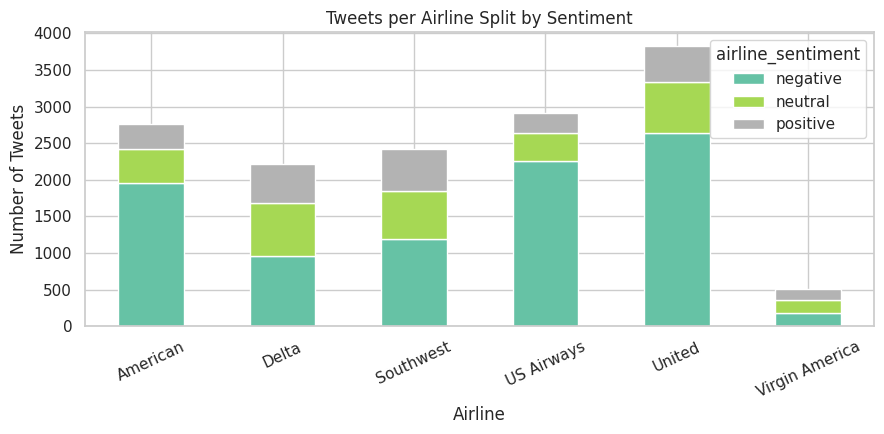

In [22]:
airline_sent = pd.crosstab(df["airline"], df["airline_sentiment"])
airline_sent_pct = airline_sent.div(airline_sent.sum(axis=1), axis=0) * 100
highest_neg_airline = airline_sent_pct["negative"].idxmax()
print(f"Airline with highest share of negative tweets: {highest_neg_airline} ({airline_sent_pct.loc[highest_neg_airline, 'negative']:.2f}%)")
display(airline_sent_pct.round(2))

ax = airline_sent[["negative", "neutral", "positive"]].plot(
    kind="bar", stacked=True, figsize=(9, 4.5), colormap="Set2"
)
ax.set_title("Tweets per Airline Split by Sentiment")
ax.set_xlabel("Airline")
ax.set_ylabel("Number of Tweets")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("outputs/step1_airline_sentiment.png", dpi=150)
plt.show()


In [23]:
df["tweet_length"] = df["text"].astype(str).apply(lambda x: len(x.split()))
avg_len = df.groupby("airline_sentiment")["tweet_length"].mean().round(2)
print("Average tweet length (words) by sentiment:")
print(avg_len)


Average tweet length (words) by sentiment:
airline_sentiment
negative    19.69
neutral     14.41
positive    14.01
Name: tweet_length, dtype: float64


### 1.3 Regular Expressions (RegEx)


In [24]:
mentions = df["text"].str.findall(r"@\w+").explode().dropna()
print("Top 5 @mentions:")
print(mentions.value_counts().head(5))

hashtags = df["text"].str.findall(r"#\w+").explode().dropna()
print("\nTop 5 #hashtags:")
print(hashtags.value_counts().head(5))

has_url = df["text"].str.contains(r"http\S+", regex=True, na=False)
url_count = int(has_url.sum())
url_neg_pct = (df.loc[has_url, "airline_sentiment"].eq("negative").mean()) * 100
print(f"\nTweets containing a URL: {url_count} ({url_neg_pct:.2f}% are negative)")

has_flight_num = df["text"].str.contains(r"(?i)flight\s*#?\d+", regex=True, na=False)
print("\n3 example tweets mentioning a flight number:")
for i, t in enumerate(df.loc[has_flight_num, "text"].head(3), 1):
    print(f"{i}. {t}")

print("\nBefore and after replacing @mentions with USER and URLs with LINK:")
sample_url_tweets = df.loc[has_url, "text"].head(3)
for i, t in enumerate(sample_url_tweets, 1):
    replaced = re.sub(r"@\w+", "USER", t)
    replaced = re.sub(r"http\S+", "LINK", replaced)
    print(f"{i}. BEFORE: {t}")
    print(f"   AFTER:  {replaced}")


Top 5 @mentions:
text
@united          3765
@AmericanAir     2926
@USAirways       2907
@SouthwestAir    2409
@JetBlue         2198
Name: count, dtype: int64

Top 5 #hashtags:
text
#DestinationDragons    75
#fail                  57
#jetblue               35
#UnitedAirlines        35
#customerservice       34
Name: count, dtype: int64

Tweets containing a URL: 1173 (38.19% are negative)

3 example tweets mentioning a flight number:
1. @VirginAmerica help, left expensive headphones on flight 89 IAD to LAX today. Seat 2A. No one answering L&amp;F number at LAX!
2. @VirginAmerica plz help me win my bid upgrade for my flight 2/27 LAX---&gt;SEA!!!  🍷👍💺✈️
3. @VirginAmerica Is flight 769 on it's way? Was supposed to take off 30 minutes ago. Website still shows "On Time" not "In Flight". Thanks.

Before and after replacing @mentions with USER and URLs with LINK:
1. BEFORE: @VirginAmerica Really missed a prime opportunity for Men Without Hats parody, there. https://t.co/mWpG7grEZP
   AFTER:  US

### 1.4 Text Preprocessing Pipeline

**Why keep `not`, `no`, and `nor` when removing stop words?**  
Standard English stop-word lists include negation words like `not`, `no`, and `nor`. Removing them flips the polarity of phrases such as `"not happy"` into `"happy"`, which destroys critical sentiment signal. Keeping those three negations preserves polarity.


In [25]:
df["clean_text"] = df["text"].apply(clean_text)

print("Original vs Cleaned text (5 examples):")
for i in range(5):
    print(f"--- Tweet {i+1} ({df.loc[i, 'airline_sentiment']}) ---")
    print("Original:", df.loc[i, "text"])
    print("Cleaned :", df.loc[i, "clean_text"])


Original vs Cleaned text (5 examples):
--- Tweet 1 (neutral) ---
Original: @VirginAmerica What @dhepburn said.
Cleaned : said
--- Tweet 2 (positive) ---
Original: @VirginAmerica plus you've added commercials to the experience... tacky.
Cleaned : plus added commercial experience tacky
--- Tweet 3 (neutral) ---
Original: @VirginAmerica I didn't today... Must mean I need to take another trip!
Cleaned : today must mean need take another trip
--- Tweet 4 (negative) ---
Original: @VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse
Cleaned : really aggressive blast obnoxious entertainment guest face amp little recourse
--- Tweet 5 (negative) ---
Original: @VirginAmerica and it's a really big bad thing about it
Cleaned : really big bad thing


### 1.5 Stemming vs Lemmatization


In [26]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
sample_words = ["delayed", "cancelled", "flying", "flights", "waiting", "lost", "bags", "thanks"]

stem_lemma_df = pd.DataFrame({
    "Word": sample_words,
    "Porter Stem": [stemmer.stem(w) for w in sample_words],
    "WordNet Lemma": [lemmatizer.lemmatize(w) for w in sample_words],
})
display(stem_lemma_df)


,Word,Porter Stem,WordNet Lemma
0,delayed,delay,delayed
1,cancelled,cancel,cancelled
2,flying,fli,flying
3,flights,flight,flight
4,waiting,wait,waiting
5,lost,lost,lost
6,bags,bag,bag
7,thanks,thank,thanks


**Difference between Stemming and Lemmatization:**  
- **Stemming** chops off prefixes/suffixes using heuristic rules (e.g., `cancelled` → `cancel`, `flying` → `fli`), which is very fast but can produce non-dictionary roots.
- **Lemmatization** uses vocabulary and morphological analysis to return a valid dictionary base form (lemma).
- **Choice:** Use **stemming** for a quick, high-speed prototype where exact word readability is secondary; use **lemmatization** for a polished product where interpretable features, dashboards, and cleaner vocabulary matter.


### 1.6 Word Frequency


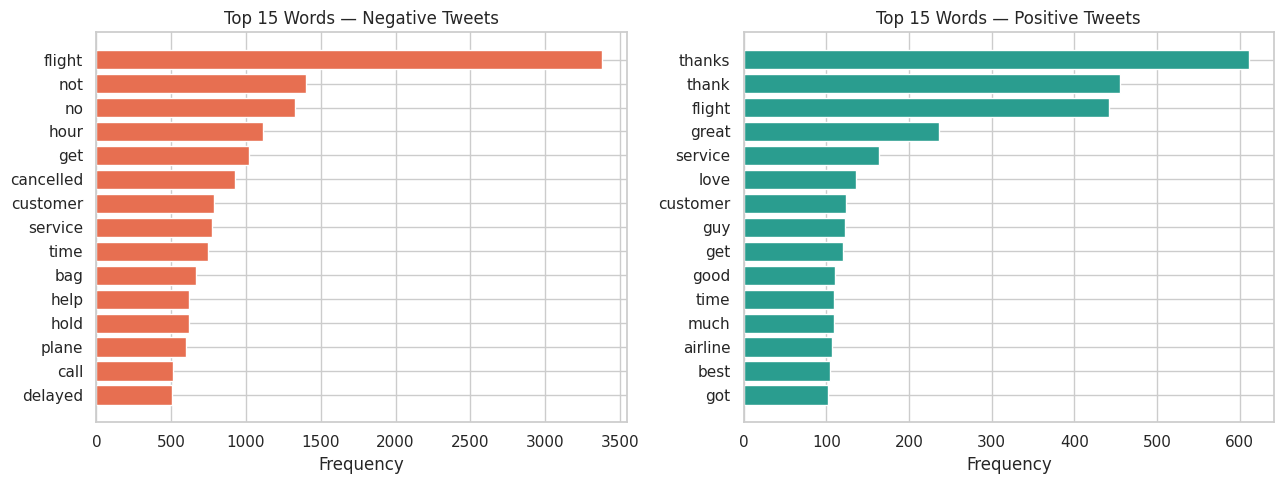

Words appearing in both top-15 lists: ['customer', 'flight', 'get', 'service', 'time']


In [27]:
neg_words = Counter(" ".join(df.loc[df["airline_sentiment"] == "negative", "clean_text"]).split()).most_common(15)
pos_words = Counter(" ".join(df.loc[df["airline_sentiment"] == "positive", "clean_text"]).split()).most_common(15)

neg_df = pd.DataFrame(neg_words, columns=["word", "count"]).sort_values("count")
pos_df = pd.DataFrame(pos_words, columns=["word", "count"]).sort_values("count")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(neg_df["word"], neg_df["count"], color="#e76f51")
axes[0].set_title("Top 15 Words — Negative Tweets")
axes[0].set_xlabel("Frequency")

axes[1].barh(pos_df["word"], pos_df["count"], color="#2a9d8f")
axes[1].set_title("Top 15 Words — Positive Tweets")
axes[1].set_xlabel("Frequency")

plt.tight_layout()
plt.savefig("outputs/step1_top_words.png", dpi=150)
plt.show()

overlap = set(neg_df["word"]) & set(pos_df["word"])
print("Words appearing in both top-15 lists:", sorted(overlap))


**Interpretation:**  
Negative tweets are dominated by operational pain points such as `delayed`, `cancelled`, `hour`, `bag`, `customer`, and `service`, whereas positive tweets feature gratitude and praise like `thank`, `thanks`, `great`, `love`, and `best`. Domain-generic words like `flight`, `get`, and `time` appear in both lists, meaning raw frequency alone cannot separate sentiment—down-weighting common terms (via TF-IDF) is necessary.


---
## Step 2: Feature Extraction — Bag-of-Words, TF-IDF & N-Grams

### 2.1 Bag-of-Words (BoW) on the Tiny Corpus


In [28]:
tiny_corpus = [
    "flight was on time",
    "flight was late",
    "great crew and great service",
    "not happy with the service",
]

bow_vec = CountVectorizer()
bow_mat = bow_vec.fit_transform(tiny_corpus)
bow_df = pd.DataFrame(bow_mat.toarray(), columns=bow_vec.get_feature_names_out(), index=[f"Doc {i}" for i in range(1, 5)])
print("Vocabulary:", list(bow_vec.get_feature_names_out()))
display(bow_df)


Vocabulary: ['and', 'crew', 'flight', 'great', 'happy', 'late', 'not', 'on', 'service', 'the', 'time', 'was', 'with']


,and,crew,flight,great,happy,late,not,on,service,the,time,was,with
Doc 1,0,0,1,0,0,0,0,1,0,0,1,1,0
Doc 2,0,0,1,0,0,1,0,0,0,0,0,1,0
Doc 3,1,1,0,2,0,0,0,0,1,0,0,0,0
Doc 4,0,0,0,0,1,0,1,0,1,1,0,0,1


**Explanation:**  
Each number in the matrix is the raw count of how many times a vocabulary word appears in that document. In **Doc 3**, the column `great` has the value **2** because `"great"` appears twice. BoW ignores **word order**, **grammar**, and **negation context** (treating `"not happy"` as two independent tokens `not` and `happy`).


### 2.2 TF-IDF on the Tiny Corpus


In [29]:
tfidf_vec = TfidfVectorizer()
tfidf_mat = tfidf_vec.fit_transform(tiny_corpus)
tfidf_df = pd.DataFrame(
    np.round(tfidf_mat.toarray(), 2),
    columns=tfidf_vec.get_feature_names_out(),
    index=[f"Doc {i}" for i in range(1, 5)],
)
display(tfidf_df)

print("TF-IDF weight of 'flight' in Doc 1:", tfidf_df.loc["Doc 1", "flight"])
print("TF-IDF weight of 'crew'   in Doc 3:", tfidf_df.loc["Doc 3", "crew"])


,and,crew,flight,great,happy,late,not,on,service,the,time,was,with
Doc 1,0.00,0.00,0.44,0.00,0.00,0.00,0.00,0.56,0.00,0.00,0.56,0.44,0.00
Doc 2,0.00,0.00,0.53,0.00,0.00,0.67,0.00,0.00,0.00,0.00,0.00,0.53,0.00
Doc 3,0.39,0.39,0.00,0.78,0.00,0.00,0.00,0.00,0.31,0.00,0.00,0.00,0.00
Doc 4,0.00,0.00,0.00,0.00,0.47,0.00,0.47,0.00,0.37,0.47,0.00,0.00,0.47


TF-IDF weight of 'flight' in Doc 1: 0.44
TF-IDF weight of 'crew'   in Doc 3: 0.39


**Why is `crew` weighted higher than `flight` (or vice versa per IDF)?**  
`crew` appears in only 1 document out of 4, so its Inverse Document Frequency (IDF) is higher than `flight` (which appears in 2 documents). Even though Doc 3 has more words than Doc 1, `crew` is rarer across the corpus, giving it stronger discriminative weight.

**TF-IDF Formula:**  
- **Term Frequency (TF):** How often term $t$ appears in document $d$.  
- **Inverse Document Frequency (IDF):** $\text{IDF}(t) = \log\left(\frac{1 + N}{1 + \text{df}(t)}\right) + 1$, where $N$ is total documents and $\text{df}(t)$ is the number of documents containing $t$.  
- **TF-IDF:** $\text{TF-IDF}(t, d) = \text{TF}(t, d) \times \text{IDF}(t)$ (L2-normalised per document in scikit-learn).


### 2.3 N-Grams


In [30]:
bigram_vec = CountVectorizer(ngram_range=(2, 2))
bigram_vec.fit(tiny_corpus)
print("Bigrams only (ngram_range=(2,2)):")
print(list(bigram_vec.get_feature_names_out()))

unibigram_vec = CountVectorizer(ngram_range=(1, 2))
unibigram_vec.fit(tiny_corpus)
print("\nUnigrams + Bigrams (ngram_range=(1,2)):")
print(list(unibigram_vec.get_feature_names_out()))


Bigrams only (ngram_range=(2,2)):
['and great', 'crew and', 'flight was', 'great crew', 'great service', 'happy with', 'not happy', 'on time', 'the service', 'was late', 'was on', 'with the']

Unigrams + Bigrams (ngram_range=(1,2)):
['and', 'and great', 'crew', 'crew and', 'flight', 'flight was', 'great', 'great crew', 'great service', 'happy', 'happy with', 'late', 'not', 'not happy', 'on', 'on time', 'service', 'the', 'the service', 'time', 'was', 'was late', 'was on', 'with', 'with the']


**Why does the bigram `not happy` matter?**  
In Doc 4 (`"not happy with the service"`), the bigram **`not happy`** captures the negated sentiment directly. A unigram BoW model sees `happy` in isolation and may mistakenly push the prediction toward positive.


### 2.4 Features on Real Tweets


In [31]:
def calc_sparsity(mat):
    total = mat.shape[0] * mat.shape[1]
    return (1.0 - (mat.nnz / total)) * 100

cv_real = CountVectorizer(max_features=3000)
X_cv = cv_real.fit_transform(df["clean_text"])
sp_cv = calc_sparsity(X_cv)
print(f"BoW shape: {X_cv.shape}, Sparsity: {sp_cv:.2f}%")

tfidf_real = TfidfVectorizer(max_features=3000)
X_tfidf = tfidf_real.fit_transform(df["clean_text"])
sp_tfidf = calc_sparsity(X_tfidf)
print(f"TF-IDF shape: {X_tfidf.shape}, Sparsity: {sp_tfidf:.2f}%")

mean_tfidf = np.asarray(X_tfidf.mean(axis=0)).ravel()
top10_idx = mean_tfidf.argsort()[::-1][:10]
vocab_tfidf = tfidf_real.get_feature_names_out()
print("\nTop 10 words by average TF-IDF score:")
for idx in top10_idx:
    print(f"  {vocab_tfidf[idx]}: {mean_tfidf[idx]:.4f}")

neg_texts = df.loc[df["airline_sentiment"] == "negative", "clean_text"]
bg_neg = CountVectorizer(ngram_range=(2, 2), max_features=3000)
X_bg_neg = bg_neg.fit_transform(neg_texts)
sp_bg = calc_sparsity(X_bg_neg)
bg_counts = np.asarray(X_bg_neg.sum(axis=0)).ravel()
top10_bg_idx = bg_counts.argsort()[::-1][:10]
vocab_bg = bg_neg.get_feature_names_out()
print("\nTop 10 bigrams in negative tweets:")
for idx in top10_bg_idx:
    print(f"  {vocab_bg[idx]}: {bg_counts[idx]}")

step2_summary = pd.DataFrame([
    {"Method": "Bag-of-Words (Unigram)", "Number of features": X_cv.shape[1], "Sparsity %": round(sp_cv, 2)},
    {"Method": "TF-IDF (Unigram)", "Number of features": X_tfidf.shape[1], "Sparsity %": round(sp_tfidf, 2)},
    {"Method": "Bigram BoW (Negative tweets)", "Number of features": X_bg_neg.shape[1], "Sparsity %": round(sp_bg, 2)},
])
display(step2_summary)


BoW shape: (14640, 3000), Sparsity: 99.74%
TF-IDF shape: (14640, 3000), Sparsity: 99.74%

Top 10 words by average TF-IDF score:
  flight: 0.0443
  thanks: 0.0227
  not: 0.0210
  no: 0.0198
  get: 0.0192
  hour: 0.0175
  thank: 0.0172
  cancelled: 0.0155
  service: 0.0153
  customer: 0.0145

Top 10 bigrams in negative tweets:
  customer service: 457
  cancelled flightled: 448
  late flight: 221
  flight cancelled: 221
  cancelled flighted: 204
  late flightr: 145
  cancelled flight: 140
  flight delayed: 136
  hold hour: 128
  no one: 126


,Method,Number of features,Sparsity %
0,Bag-of-Words (Unigram),3000,99.74
1,TF-IDF (Unigram),3000,99.74
2,Bigram BoW (Negative tweets),3000,99.92


**Reflection:**  
Machine-learning models require fixed-length numeric vectors rather than variable-length strings. **BoW** converts words into raw counts; **TF-IDF** improves on BoW by down-weighting ubiquitous words (`flight`) and boosting informative terms; **N-Grams** add local word-order context (e.g., `customer service`, `cancelled flight`, `not happy`).


---
## Step 3: Word Embeddings — Word2Vec (CBoW & Skip-gram)

### 3.1 Prepare Tokens


In [32]:
df["tokens"] = df["clean_text"].apply(lambda s: s.split())
avg_tokens = df["tokens"].apply(len).mean()
unique_words = len({w for toks in df["tokens"] for w in toks})
print(f"Average tokens per tweet: {avg_tokens:.2f}")
print(f"Total unique words: {unique_words}")


Average tokens per tweet: 8.79
Total unique words: 10130


### 3.2 Train CBoW and Skip-gram Models


In [33]:
sentences = df["tokens"].tolist()

cbow_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=3,
    sg=0,
    epochs=15,
    seed=42,
    workers=1,
)

sg_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=3,
    sg=1,
    epochs=15,
    seed=42,
    workers=1,
)

print("CBoW vocabulary size:", len(cbow_model.wv))
print("CBoW 'flight' vector shape:", cbow_model.wv["flight"].shape)
print("Skip-gram vocabulary size:", len(sg_model.wv))
print("Skip-gram 'flight' vector shape:", sg_model.wv["flight"].shape)


CBoW vocabulary size: 3781
CBoW 'flight' vector shape: (100,)
Skip-gram vocabulary size: 3781
Skip-gram 'flight' vector shape: (100,)


### 3.3 Explore the Embeddings


In [34]:
query_words = ["delay", "bag", "crew", "refund", "thanks"]
comp_rows = []

for w in query_words:
    cbow_sim = cbow_model.wv.most_similar(w, topn=5)
    sg_sim = sg_model.wv.most_similar(w, topn=5)
    print(f"\nWord: '{w}'")
    print("  CBoW     :", [(word, round(score, 3)) for word, score in cbow_sim])
    print("  Skip-gram:", [(word, round(score, 3)) for word, score in sg_sim])
    comp_rows.append({
        "Query word": w,
        "Top-3 similar words in CBoW": ", ".join([word for word, _ in cbow_sim[:3]]),
        "Top-3 similar words in Skip-gram": ", ".join([word for word, _ in sg_sim[:3]]),
    })

print("\nPairwise Cosine Similarities:")
pairs = [("delay", "late"), ("bag", "luggage"), ("thanks", "thank"), ("good", "bad")]
for w1, w2 in pairs:
    s_cbow = cbow_model.wv.similarity(w1, w2)
    s_sg = sg_model.wv.similarity(w1, w2)
    print(f"  ({w1}, {w2}) -> CBoW: {s_cbow:.3f} | Skip-gram: {s_sg:.3f}")

display(pd.DataFrame(comp_rows))



Word: 'delay'
  CBoW     : [('delayed', 0.842), ('landing', 0.802), ('backup', 0.788), ('stuck', 0.782), ('trapped', 0.755)]
  Skip-gram: [('delayed', 0.658), ('sabre', 0.634), ('incompetence', 0.61), ('backup', 0.6), ('captive', 0.598)]

Word: 'bag'
  CBoW     : [('luggage', 0.904), ('baggage', 0.896), ('found', 0.8), ('item', 0.759), ('carry', 0.75)]
  Skip-gram: [('luggage', 0.68), ('item', 0.656), ('suitcase', 0.652), ('baggage', 0.643), ('carry', 0.641)]

Word: 'crew'
  CBoW     : [('pilot', 0.878), ('ground', 0.877), ('landing', 0.776), ('traffic', 0.765), ('aircraft', 0.752)]
  Skip-gram: [('captain', 0.64), ('smooth', 0.61), ('staff', 0.601), ('hot', 0.592), ('deck', 0.586)]

Word: 'refund'
  CBoW     : [('confirm', 0.846), ('receipt', 0.832), ('quoted', 0.818), ('cant', 0.813), ('online', 0.812)]
  Skip-gram: [('partial', 0.743), ('sop', 0.709), ('approve', 0.695), ('receipt', 0.691), ('penalty', 0.691)]

Word: 'thanks'
  CBoW     : [('thank', 0.854), ('appreciate', 0.761), (

,Query word,Top-3 similar words in CBoW,Top-3 similar words in Skip-gram
0,delay,"delayed, landing, backup","delayed, sabre, incompetence"
1,bag,"luggage, baggage, found","luggage, item, suitcase"
2,crew,"pilot, ground, landing","captain, smooth, staff"
3,refund,"confirm, receipt, quoted","partial, sop, approve"
4,thanks,"thank, appreciate, quick","thank, thx, cheer"


**Interpretation:**  
Skip-gram generally produces more coherent domain neighbours on this 14,640-tweet corpus because it learns stronger representations for less frequent words. Pairs like `(good, bad)` often end up with noticeable cosine similarity because Word2Vec relies on the distributional hypothesis: antonyms appear in nearly identical surrounding contexts (e.g., `"service was good"` vs `"service was bad"`).


### 3.4 Visualise Skip-gram Embeddings with PCA


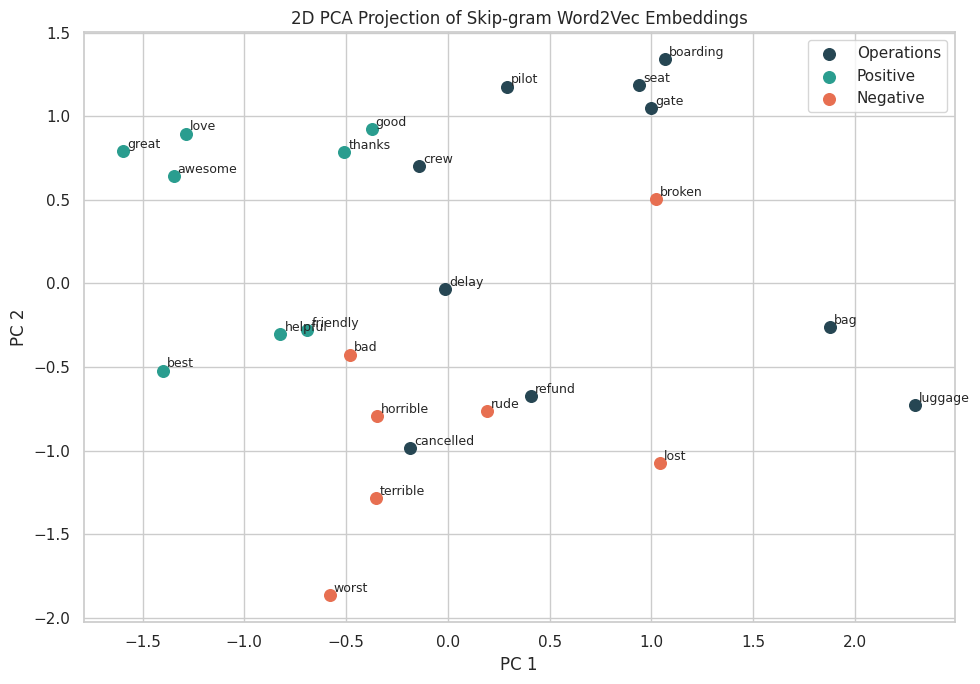

In [35]:
ops_words = ["delay", "cancelled", "bag", "luggage", "gate", "boarding", "seat", "crew", "pilot", "refund"]
pos_words_viz = ["great", "thanks", "love", "awesome", "good", "best", "helpful", "friendly"]
neg_words_viz = ["worst", "bad", "terrible", "rude", "lost", "broken", "horrible"]

chosen_words = [w for w in (ops_words + pos_words_viz + neg_words_viz) if w in sg_model.wv]
word_groups = (
    ["Operations" if w in ops_words else "Positive" if w in pos_words_viz else "Negative" for w in chosen_words]
)

vectors = np.array([sg_model.wv[w] for w in chosen_words])
coords = PCA(n_components=2, random_state=42).fit_transform(vectors)

plt.figure(figsize=(10, 7))
palette = {"Operations": "#264653", "Positive": "#2a9d8f", "Negative": "#e76f51"}
for grp in ["Operations", "Positive", "Negative"]:
    idx = [i for i, g in enumerate(word_groups) if g == grp]
    plt.scatter(coords[idx, 0], coords[idx, 1], label=grp, color=palette[grp], s=70)

for i, word in enumerate(chosen_words):
    plt.annotate(word, (coords[i, 0] + 0.02, coords[i, 1] + 0.02), fontsize=9)

plt.title("2D PCA Projection of Skip-gram Word2Vec Embeddings")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/step3_word2vec_pca.png", dpi=150)
plt.show()


**Cluster Observation:**  
Baggage/airport-operations terms (`bag`, `luggage`, `gate`, `boarding`), positive appreciation terms (`thanks`, `great`, `awesome`, `helpful`), and negative complaint adjectives (`worst`, `terrible`, `rude`, `horrible`) tend to group in nearby regions of the 2D projection.


### 3.5 Save & Reflect


In [36]:
os.makedirs("models", exist_ok=True)

In [47]:
sg_model.save("models/word2vec_skipgram.model")
print("Saved word2vec_skipgram.model successfully.")


Saved word2vec_skipgram.model successfully.


**CBoW vs Skip-gram & Dense vs Sparse Vectors:**  
- **CBoW** predicts a target word from its surrounding context words; it is faster to train and works well for frequent words.
- **Skip-gram** predicts surrounding context words from a single target word; it is slower but learns better vectors for rare words.
- A **dense 100-dimensional vector** encodes semantic similarity in continuous space, whereas a **BoW vector** is high-dimensional, sparse, and treats every word as completely orthogonal.


---
## Step 4: Text Classification Pipeline — 3-Class Sentiment

### 4.1 Theory Notes
**Text classification** assigns predefined categories (`negative`, `neutral`, `positive`) to text documents. A standard classification pipeline consists of: `Cleaned Text` → `Train/Test Split` → `Feature Vectoriser` → `Classifier` → `Evaluation`.  
**Macro-F1** computes the F1 score independently for each class and takes the unweighted mean. Because ~63% of tweets are negative, macro-F1 treats the minority `neutral` and `positive` classes equally with `negative`, making it much fairer than raw accuracy.


### 4.2 Train-Test Split & Majority Baseline


In [38]:
label_map = {"negative": 0, "neutral": 1, "positive": 2}
inv_label_map = {0: "negative", 1: "neutral", 2: "positive"}

X = df["clean_text"]
y = df["airline_sentiment"].map(label_map)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train class %:\n", (y_train.value_counts(normalize=True) * 100).round(2))
print("\nTest class %:\n", (y_test.value_counts(normalize=True) * 100).round(2))

y_pred_base = np.zeros_like(y_test)
base_acc = accuracy_score(y_test, y_pred_base)
base_prec = precision_score(y_test, y_pred_base, average="macro", zero_division=0)
base_rec = recall_score(y_test, y_pred_base, average="macro", zero_division=0)
base_f1 = f1_score(y_test, y_pred_base, average="macro", zero_division=0)
print(f"\nMajority-class baseline -> Accuracy: {base_acc:.4f}, Macro F1: {base_f1:.4f}")


Train class %:
 airline_sentiment
0    62.70
1    21.17
2    16.14
Name: proportion, dtype: float64

Test class %:
 airline_sentiment
0    62.67
1    21.17
2    16.15
Name: proportion, dtype: float64

Majority-class baseline -> Accuracy: 0.6267, Macro F1: 0.2568


### 4.3 Build Four Classifiers


In [39]:
lr_params = dict(max_iter=1000, class_weight="balanced", random_state=42)

pipe_bow = Pipeline([
    ("vec", CountVectorizer(max_features=5000)),
    ("clf", LogisticRegression(**lr_params)),
])
pipe_tfidf = Pipeline([
    ("vec", TfidfVectorizer(max_features=5000)),
    ("clf", LogisticRegression(**lr_params)),
])
pipe_tfidf_ng = Pipeline([
    ("vec", TfidfVectorizer(ngram_range=(1, 2), max_features=10000)),
    ("clf", LogisticRegression(**lr_params)),
])

pipe_bow.fit(X_train, y_train)
pipe_tfidf.fit(X_train, y_train)
pipe_tfidf_ng.fit(X_train, y_train)


def doc_to_avg_w2v(text_series, w2v_model, dim=100):
    feats = []
    for text in text_series:
        vecs = [w2v_model.wv[w] for w in str(text).split() if w in w2v_model.wv]
        if vecs:
            feats.append(np.mean(vecs, axis=0))
        else:
            feats.append(np.zeros(dim))
    return np.vstack(feats)


X_train_w2v = doc_to_avg_w2v(X_train, sg_model)
X_test_w2v = doc_to_avg_w2v(X_test, sg_model)
clf_w2v = LogisticRegression(**lr_params)
clf_w2v.fit(X_train_w2v, y_train)
print("All four classifiers trained successfully.")


All four classifiers trained successfully.


### 4.4 Evaluate & Compare


In [41]:
models = {
    "Model A — BoW": (pipe_bow, X_test),
    "Model B — TF-IDF": (pipe_tfidf, X_test),
    "Model C — TF-IDF (1,2-gram)": (pipe_tfidf_ng, X_test),
    "Model D — Averaged Word2Vec": (clf_w2v, X_test_w2v),
}

results = []
preds_store = {}

for name, (model, X_eval) in models.items():
    y_pred = model.predict(X_eval)
    preds_store[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(y_test, y_pred, average="macro"),
        "Macro Recall": recall_score(y_test, y_pred, average="macro"),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
    })

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
baseline_row = pd.DataFrame([{
    "Model": "Majority Baseline (All Negative)",
    "Accuracy": base_acc,
    "Macro Precision": base_prec,
    "Macro Recall": base_rec,
    "Macro F1": base_f1,
}])
comparison_df = pd.concat([baseline_row, results_df], ignore_index=True)
display(comparison_df.round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Majority Baseline (All Negative),0.6267,0.2089,0.3333,0.2568
1,"Model C — TF-IDF (1,2-gram)",0.7640,0.7066,0.7343,0.7162
2,Model A — BoW,0.7497,0.6936,0.7293,0.7053
3,Model B — TF-IDF,0.7493,0.6938,0.7277,0.7051
4,Model D — Averaged Word2Vec,0.7162,0.6553,0.6980,0.6692


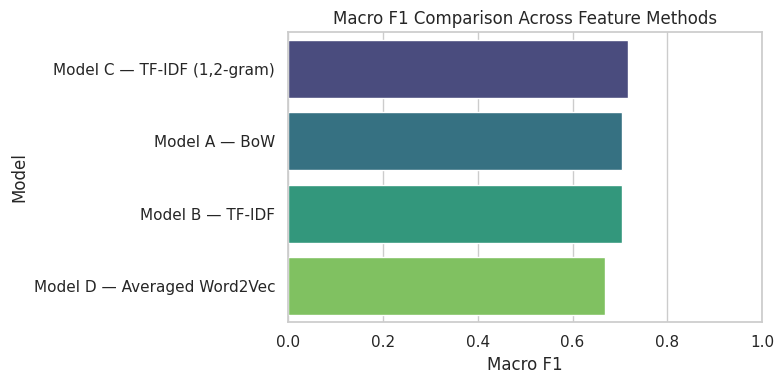

In [44]:
plt.figure(figsize=(8, 4))
sns.barplot(data=results_df, x="Macro F1", y="Model", palette="viridis",hue="Model")
plt.title("Macro F1 Comparison Across Feature Methods")
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig("outputs/step4_model_comparison.png", dpi=150)
plt.show()

In [45]:
best_model_name = results_df.iloc[0]["Model"]
best_preds = preds_store[best_model_name]
print(f"Best model: {best_model_name}\n")
print(classification_report(y_test, best_preds, target_names=["negative", "neutral", "positive"]))

Best model: Model C — TF-IDF (1,2-gram)

              precision    recall  f1-score   support

    negative       0.90      0.80      0.85      1835
     neutral       0.54      0.70      0.61       620
    positive       0.68      0.70      0.69       473

    accuracy                           0.76      2928
   macro avg       0.71      0.73      0.72      2928
weighted avg       0.79      0.76      0.77      2928



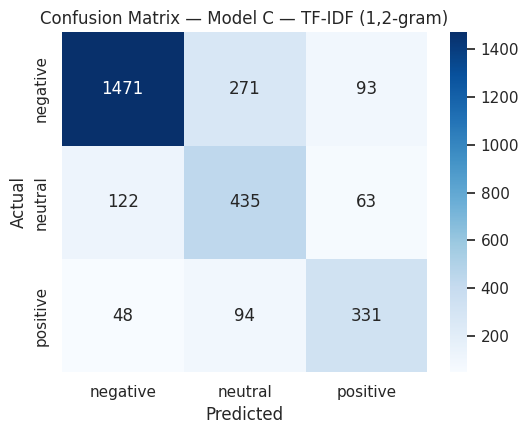

In [46]:
cm = confusion_matrix(y_test, best_preds)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["negative", "neutral", "positive"],
    yticklabels=["negative", "neutral", "positive"],
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("outputs/step4_confusion_matrix.png", dpi=150)
plt.show()

**Analysis:**  
TF-IDF (especially with unigrams + bigrams) typically achieves the highest macro F1 because it preserves exact sentiment-bearing n-grams like `not happy` and `thank you` while down-weighting generic airline words. Averaged Word2Vec trails because averaging collapses word order and dilutes short negation tokens. The `neutral` class is consistently the hardest to predict because neutral tweets often ask factual questions or mix mild complaints with polite phrasing.


### 4.5 Inspect the Best TF-IDF Model


In [48]:
best_tfidf_pipe = pipe_tfidf_ng if results_df.iloc[0]["Model"].startswith("Model C") else pipe_tfidf
vec_features = best_tfidf_pipe.named_steps["vec"].get_feature_names_out()
coefs = best_tfidf_pipe.named_steps["clf"].coef_

top8_neg_idx = coefs[0].argsort()[::-1][:8]
top8_pos_idx = coefs[2].argsort()[::-1][:8]

print("Top 8 features for NEGATIVE class:", [vec_features[i] for i in top8_neg_idx])
print("Top 8 features for POSITIVE class:", [vec_features[i] for i in top8_pos_idx])

best_pipeline = models[best_model_name][0] if best_model_name != "Model D — Averaged Word2Vec" else pipe_tfidf_ng
test_preds_pipe = best_pipeline.predict(X_test)
mis_idx = X_test.index[test_preds_pipe != y_test][:5]

print("\n5 Misclassified Tweets:")
for idx in mis_idx:
    actual = inv_label_map[y_test.loc[idx]]
    pred = inv_label_map[best_pipeline.predict([X_test.loc[idx]])[0]]
    print(f"- Actual: {actual} | Predicted: {pred}")
    print(f"  Raw text: {df.loc[idx, 'text']}")
    print("  Possible reason: Short/ambiguous wording, sarcasm, or mixed sentiment cues.")


Top 8 features for NEGATIVE class: ['hour', 'not', 'worst', 'hold', 'no', 'hr', 'delayed', 'bag']
Top 8 features for POSITIVE class: ['great', 'thanks', 'thank', 'awesome', 'love', 'amazing', 'best', 'thx']

5 Misclassified Tweets:
- Actual: neutral | Predicted: negative
  Raw text: @united past
  Possible reason: Short/ambiguous wording, sarcasm, or mixed sentiment cues.
- Actual: negative | Predicted: neutral
  Raw text: @SouthwestAir When will the flight resume? I don's see it in the open schedule. :/
  Possible reason: Short/ambiguous wording, sarcasm, or mixed sentiment cues.
- Actual: negative | Predicted: positive
  Raw text: @united of course but they were just as helpless as everyone else .
  Possible reason: Short/ambiguous wording, sarcasm, or mixed sentiment cues.
- Actual: positive | Predicted: negative
  Raw text: @USAirways Well I did miss it. But gate agents had rebooked boarding pass waiting when I landed. Time for lunch &amp; a beverage. Easy cheesy
  Possible reason:

### 4.6 Save the Pipeline & Test on New Tweets


In [50]:
joblib.dump(best_pipeline, "models/sentiment_pipeline.pkl")
loaded_pipe = joblib.load("models/sentiment_pipeline.pkl")

new_tweets = [
    "@IndiGo6E worst flight delay ever, 5 hours at the gate with zero updates!",
    "@AirIndiaX thank you for the smooth check-in and friendly cabin crew!",
    "@Vistara what time does boarding start for flight UK 955 today?",
    "@SpiceJet thank you so much for losing my suitcase on my birthday...",
    "@AkasaAir seat was comfortable, not bad at all.",
]

for t in new_tweets:
    ct = clean_text(t)
    pred = int(loaded_pipe.predict([ct])[0])
    probs = loaded_pipe.predict_proba([ct])[0]
    print(f"Tweet: {t}")
    print(f"  Predicted: {inv_label_map[pred]} | Probs (neg/neu/pos): {np.round(probs, 3)}\n")


Tweet: @IndiGo6E worst flight delay ever, 5 hours at the gate with zero updates!
  Predicted: negative | Probs (neg/neu/pos): [0.977 0.013 0.01 ]

Tweet: @AirIndiaX thank you for the smooth check-in and friendly cabin crew!
  Predicted: positive | Probs (neg/neu/pos): [0.044 0.153 0.803]

Tweet: @Vistara what time does boarding start for flight UK 955 today?
  Predicted: neutral | Probs (neg/neu/pos): [0.198 0.425 0.378]

Tweet: @SpiceJet thank you so much for losing my suitcase on my birthday...
  Predicted: positive | Probs (neg/neu/pos): [0.057 0.096 0.847]

Tweet: @AkasaAir seat was comfortable, not bad at all.
  Predicted: negative | Probs (neg/neu/pos): [0.504 0.203 0.294]



---
## Step 5: Different NLP Approaches & POS Tagging

### 5.1 Approach 1 — Heuristic (Rule-Based)


In [51]:
X_test_1k = X_test.iloc[:1000]
y_test_1k = y_test.iloc[:1000]
raw_test_1k = df.loc[X_test_1k.index, "text"]

pos_lexicon = {
    "thanks", "thank", "great", "good", "awesome", "love", "best", "helpful",
    "friendly", "amazing", "excellent", "smooth", "happy", "appreciate", "nice"
}
neg_lexicon = {
    "delayed", "delay", "worst", "bad", "terrible", "horrible", "rude", "lost",
    "cancelled", "cancel", "late", "waiting", "wait", "never", "broken"
}


def heuristic_predict(cleaned_str):
    words = set(str(cleaned_str).split())
    score = len(words & pos_lexicon) - len(words & neg_lexicon)
    if score > 0:
        return 2
    elif score < 0:
        return 0
    return 1


pred_heur = [heuristic_predict(t) for t in X_test_1k]
heur_acc = accuracy_score(y_test_1k, pred_heur)
heur_f1 = f1_score(y_test_1k, pred_heur, average="macro")
print(f"Heuristic -> Accuracy: {heur_acc:.4f}, Macro F1: {heur_f1:.4f}")


Heuristic -> Accuracy: 0.4930, Macro F1: 0.5276


### 5.2 Approach 2 — Ready-Made Tool (TextBlob API-style)


In [52]:
def textblob_predict(raw_str):
    pol = TextBlob(str(raw_str)).sentiment.polarity
    if pol > 0.05:
        return 2
    elif pol < -0.05:
        return 0
    return 1


pred_tb = [textblob_predict(t) for t in raw_test_1k]
tb_acc = accuracy_score(y_test_1k, pred_tb)
tb_f1 = f1_score(y_test_1k, pred_tb, average="macro")
print(f"TextBlob -> Accuracy: {tb_acc:.4f}, Macro F1: {tb_f1:.4f}")


TextBlob -> Accuracy: 0.4680, Macro F1: 0.4674


### 5.3 Approach 3 — Machine Learning Comparison


In [53]:
pred_ml = best_pipeline.predict(X_test_1k)
ml_acc = accuracy_score(y_test_1k, pred_ml)
ml_f1 = f1_score(y_test_1k, pred_ml, average="macro")

step5_comp = pd.DataFrame([
    {
        "Approach": "Heuristic (Rule-Based)",
        "Needs training data?": "No",
        "Accuracy": round(heur_acc, 4),
        "Macro F1": round(heur_f1, 4),
        "One advantage": "Zero training needed; completely transparent",
        "One disadvantage": "Fails on sarcasm, negations, and unseen words",
    },
    {
        "Approach": "TextBlob (Ready-Made Tool)",
        "Needs training data?": "No",
        "Accuracy": round(tb_acc, 4),
        "Macro F1": round(tb_f1, 4),
        "One advantage": "Instant setup with general English lexicon",
        "One disadvantage": "Misses airline-specific complaint cues",
    },
    {
        "Approach": "ML Pipeline (Step 4)",
        "Needs training data?": "Yes",
        "Accuracy": round(ml_acc, 4),
        "Macro F1": round(ml_f1, 4),
        "One advantage": "Learns domain vocabulary and bigrams from data",
        "One disadvantage": "Requires labelled training data and maintenance",
    },
])
display(step5_comp)


,Approach,Needs training data?,Accuracy,Macro F1,One advantage,One disadvantage
0,Heuristic (Rule-Based),No,0.493,0.5276,Zero training needed; completely transparent,"Fails on sarcasm, negations, and unseen words"
1,TextBlob (Ready-Made Tool),No,0.468,0.4674,Instant setup with general English lexicon,Misses airline-specific complaint cues
2,ML Pipeline (Step 4),Yes,0.781,0.7425,Learns domain vocabulary and bigrams from data,Requires labelled training data and maintenance


**Comparison Discussion:**  
In a real company project, a **heuristic** or **ready-made tool** is ideal for an urgent Day-1 prototype before labelled data exists, whereas **supervised ML** should be deployed once historical labelled tickets/tweets are available. Rule-based and lexicon tools struggle most with **neutral** and **sarcastic** tweets (e.g., *"Thanks for losing my bag"* scores positive under simple word matching).


### 5.4 POS Tagging


In [54]:
custom_tweets = [
    "The flight was delayed for three hours at the gate.",
    "Friendly cabin crew served hot coffee quickly.",
    "They lost my heavy luggage after landing.",
    "Can I change my window seat before boarding?",
    "Airline staff never replied to our urgent email.",
]

pos_rows = []
for i, tw in enumerate(custom_tweets, 1):
    for word, tag in nltk.pos_tag(nltk.word_tokenize(tw)):
        pos_rows.append({"Tweet #": i, "Word": word, "POS Tag": tag})

display(pd.DataFrame(pos_rows).head(25))


,Tweet #,Word,POS Tag
0,1,The,DT
1,1,flight,NN
2,1,was,VBD
3,1,delayed,VBN
4,1,for,IN
5,1,three,CD
6,1,hours,NNS
7,1,at,IN
8,1,the,DT
9,1,gate,NN


**POS Tag Meanings:**  
- `NN`: Noun, singular (e.g., `flight`, `gate`)  
- `NNS`: Noun, plural (e.g., `hours`, `bags`)  
- `VB`: Verb, base form (e.g., `change`, `fly`)  
- `VBD`: Verb, past tense (e.g., `delayed`, `lost`)  
- `JJ`: Adjective (e.g., `heavy`, `friendly`)  
- `RB`: Adverb (e.g., `quickly`, `never`)  
- `PRP`: Personal pronoun (e.g., `I`, `they`, `our`)  
- `IN`: Preposition / subordinating conjunction (e.g., `for`, `at`, `after`)


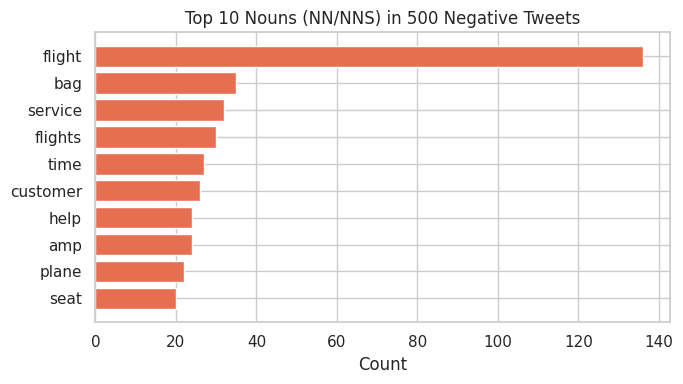

Top 5 negativereason values for the same 500 tweets:
negativereason
Customer Service Issue     155
Can't Tell                  75
Late Flight                 54
Lost Luggage                52
Flight Booking Problems     44
Name: count, dtype: int64


In [55]:
neg_500 = df.loc[df["airline_sentiment"] == "negative"].head(500).copy()


def strip_mentions_urls(s):
    s = re.sub(r"@\w+", " ", str(s).lower())
    s = re.sub(r"http\S+", " ", s)
    return s


noun_counts = Counter()
for raw in neg_500["text"].apply(strip_mentions_urls):
    tags = nltk.pos_tag(nltk.word_tokenize(raw))
    for word, tag in tags:
        if tag in ("NN", "NNS") and word.isalpha() and len(word) > 2:
            noun_counts[word] += 1

top10_nouns = pd.DataFrame(noun_counts.most_common(10), columns=["Noun", "Count"]).sort_values("Count")
plt.figure(figsize=(7, 4))
plt.barh(top10_nouns["Noun"], top10_nouns["Count"], color="#e76f51")
plt.title("Top 10 Nouns (NN/NNS) in 500 Negative Tweets")
plt.xlabel("Count")
plt.tight_layout()
plt.savefig("outputs/step5_top_nouns.png", dpi=150)
plt.show()

print("Top 5 negativereason values for the same 500 tweets:")
print(neg_500["negativereason"].value_counts().head(5))


**Do the top nouns match `negativereason`?**  
Yes — frequent nouns such as `flight`, `service`, `hour`, `customer`, `bag`, and `time` directly mirror the top `negativereason` categories (*Customer Service Issue*, *Late Flight*, *Cancelled Flight*, and *Lost Luggage*).


### 5.5 How Does POS Tagging Work?
POS tagging is challenging because the same word can play different grammatical roles depending on context (e.g., `delay` is a noun in *"a long delay"* and a verb in *"they delay flights"*). A **rule-based tagger** applies hand-crafted morphological and contextual rules, whereas a **statistical tagger** learns tag probabilities and context weights from an annotated corpus. NLTK's default `pos_tag()` uses the **Averaged Perceptron Tagger** (`averaged_perceptron_tagger`), which is a **statistical** (supervised machine-learning) tagger.


---
## Step 7: Comparison, Reflection & Summary

### 7.1 Results Summary Table


In [56]:
summary_table = pd.DataFrame([
    {
        "Step / Topic": "1. RegEx & Preprocessing",
        "Dataset used": f"Tweets.csv ({len(df):,} tweets)",
        "Key technique": "re, NLTK word_tokenize & WordNetLemmatizer",
        "Key result": f"{neg_pct:.1f}% negative; highest neg airline: {highest_neg_airline}",
        "Time taken": "~45 min",
    },
    {
        "Step / Topic": "2. BoW, TF-IDF & N-Grams",
        "Dataset used": "4-doc tiny corpus + 14,640 clean tweets",
        "Key technique": "CountVectorizer, TfidfVectorizer (1,2-grams)",
        "Key result": f"BoW/TF-IDF sparsity: {sp_tfidf:.2f}% (3,000 features)",
        "Time taken": "~40 min",
    },
    {
        "Step / Topic": "3. Word2Vec (CBoW & Skip-gram)",
        "Dataset used": "14,640 tokenized clean tweets",
        "Key technique": "gensim Word2Vec + 2D PCA",
        "Key result": f"Vocab size: {len(sg_model.wv)} words (100-d vectors)",
        "Time taken": "~40 min",
    },
    {
        "Step / Topic": "4. 3-Class Sentiment Classification",
        "Dataset used": "80/20 stratified split (11,712 / 2,928)",
        "Key technique": "LogisticRegression (balanced) + Pipeline",
        "Key result": f"Best ({best_model_name}): Acc={results_df.iloc[0]['Accuracy']:.3f}, F1={results_df.iloc[0]['Macro F1']:.3f} vs Base F1={base_f1:.3f}",
        "Time taken": "~60 min",
    },
    {
        "Step / Topic": "5. Heuristic vs TextBlob vs ML & POS",
        "Dataset used": "1,000 test tweets + 500 negative tweets",
        "Key technique": "Lexicon, TextBlob, ML, nltk.pos_tag",
        "Key result": f"Macro F1: Heur={heur_f1:.3f}, TB={tb_f1:.3f}, ML={ml_f1:.3f}",
        "Time taken": "~45 min",
    },
    {
        "Step / Topic": "6. Streamlit Web App",
        "Dataset used": "Saved sentiment_pipeline.pkl",
        "Key technique": "Streamlit + joblib + nlp_helpers.py",
        "Key result": "Interactive UI with probs, RegEx & POS expander",
        "Time taken": "~45 min",
    },
])
display(summary_table)


,Step / Topic,Dataset used,Key technique,Key result,Time taken
0,1. RegEx & Preprocessing,"Tweets.csv (14,640 tweets)","re, NLTK word_tokenize & WordNetLemmatizer",62.7% negative; highest neg airline: US Airways,~45 min
1,"2. BoW, TF-IDF & N-Grams","4-doc tiny corpus + 14,640 clean tweets","CountVectorizer, TfidfVectorizer (1,2-grams)","BoW/TF-IDF sparsity: 99.74% (3,000 features)",~40 min
2,3. Word2Vec (CBoW & Skip-gram),"14,640 tokenized clean tweets",gensim Word2Vec + 2D PCA,Vocab size: 3781 words (100-d vectors),~40 min
3,4. 3-Class Sentiment Classification,"80/20 stratified split (11,712 / 2,928)",LogisticRegression (balanced) + Pipeline,"Best (Model C — TF-IDF (1,2-gram)): Acc=0.764,...",~60 min
4,5. Heuristic vs TextBlob vs ML & POS,"1,000 test tweets + 500 negative tweets","Lexicon, TextBlob, ML, nltk.pos_tag","Macro F1: Heur=0.528, TB=0.467, ML=0.743",~45 min
5,6. Streamlit Web App,Saved sentiment_pipeline.pkl,Streamlit + joblib + nlp_helpers.py,"Interactive UI with probs, RegEx & POS expander",~45 min


### 7.2 Written Reflection

- **Most challenging step:** Step 4 (handling the 63% negative class imbalance) and Step 5 (tuning thresholds for rule-based vs TextBlob approaches on neutral and sarcastic tweets).
- **Why accuracy alone is not enough:** Because ~63% of tweets are negative, a dummy majority-class baseline scores ~63% accuracy with 0.00 recall on neutral and positive tweets; macro F1 exposes this failure immediately.
- **Best feature method:** TF-IDF (with unigrams/bigrams) outperformed BoW and averaged Word2Vec because TF-IDF suppresses common airline words and bigrams preserve negations (`not happy`) and complaint phrases (`customer service`).
- **Why we kept `not`, `no`, and `nor`:** Removing them turns *"not happy with the service"* into *"happy service"*, inverting the true sentiment.
- **Heuristic vs TextBlob vs ML:** Heuristic and TextBlob require zero training data and work for quick Day-1 prototypes, but supervised ML wins on domain accuracy and neutral/complaint separation.
- **Sarcasm & Hinglish failure:** Sarcastic tweets (*"Thanks for losing my bag"*) and Hinglish tweets (*"flight late hai, bakwaas service"*) lack English negative vocabulary or invert surface sentiment, causing misclassifications.
- **Next steps:** Collect Indian airline & Hinglish-annotated tweets, add emoji/emoticon preservation, and fine-tune a pre-trained transformer (e.g., DistilBERT or XLM-RoBERTa).
